# Are happier songs more danceable?

Spotify measures a song's "happiness" with **valence**: a score from 0 (sad, angry, tense) to 1 (happy, cheerful, euphoric). **Danceability** is also scored 0 to 1, based on tempo, rhythm stability and beat strength. This notebook checks whether songs with higher valence also tend to be more danceable.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact

spotify_data = pd.read_csv("spotify_tracks_with_release.csv")

In [26]:
spotify_data.head()
spotify_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 36 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   index                            114000 non-null  int64  
 1   track_id                         114000 non-null  str    
 2   artists                          113999 non-null  str    
 3   album_name                       113999 non-null  str    
 4   track_name                       113999 non-null  str    
 5   popularity                       114000 non-null  int64  
 6   duration_ms                      114000 non-null  int64  
 7   explicit                         114000 non-null  bool   
 8   danceability                     114000 non-null  float64
 9   energy                           114000 non-null  float64
 10  key                              114000 non-null  int64  
 11  loudness                         114000 non-null  float64
 12  mode         

## Check the corr matrix

A correlation matrix of all the numeric features shows which pairs are related. Valence and danceability have r = 0.48, one of the strongest pairs that isn't an obvious loudness/energy effect.

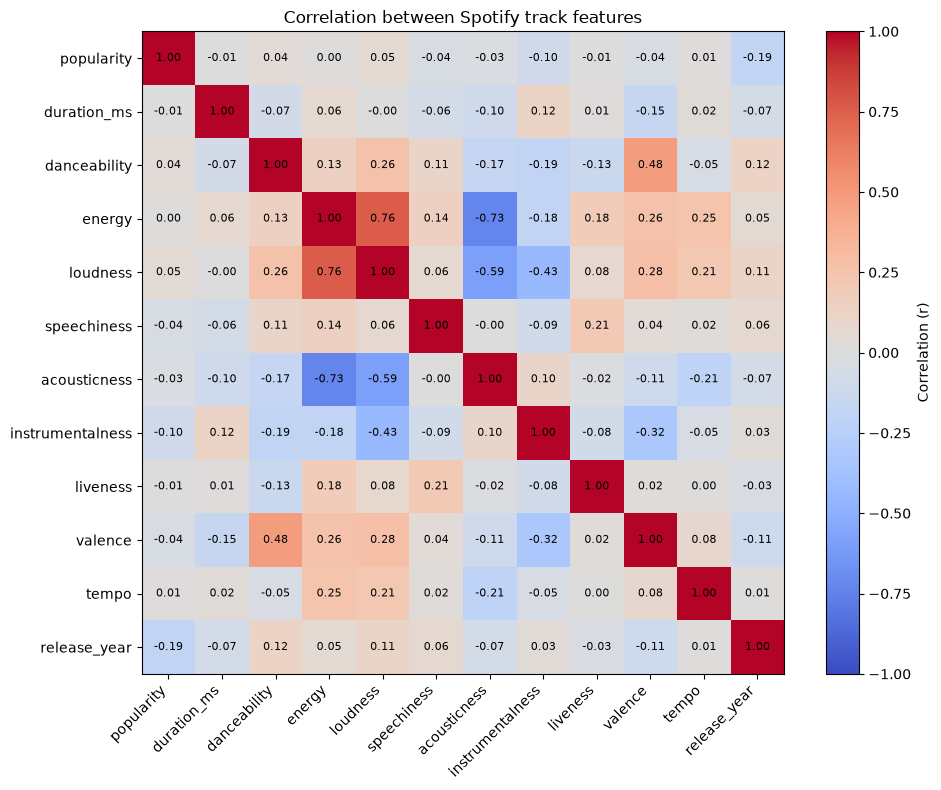

valence vs. danceability: r = 0.48


In [27]:
# Correlation matrix: how strongly each pair of numeric variables moves together
# (+1 = perfectly together, -1 = perfectly opposite, 0 = no linear relationship)
cols = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness',
        'speechiness', 'acousticness', 'instrumentalness', 'liveness',
        'valence', 'tempo', 'release_year']
corr = spotify_data[cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, label='Correlation (r)')

ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)), cols)

# Write the r value in each square
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)

ax.set_title("Correlation between Spotify track features")
plt.tight_layout()
plt.show()

print(f"valence vs. danceability: r = {corr.loc['valence', 'danceability']:.2f}")

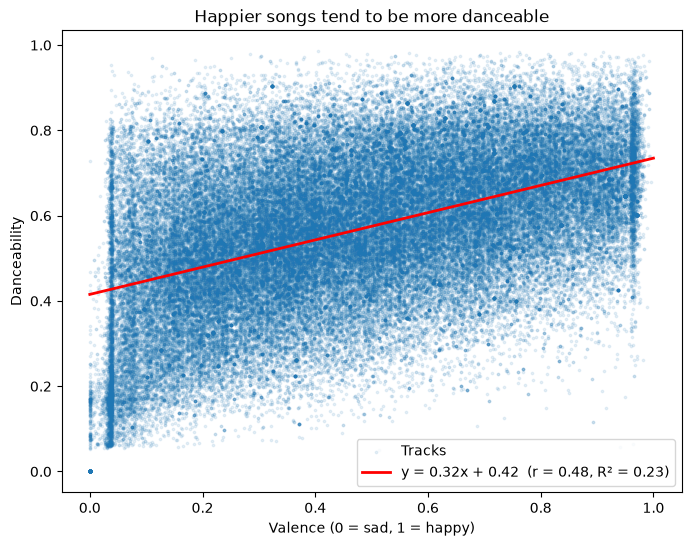

In [28]:
x = spotify_data['valence']
y = spotify_data['danceability']

# Fit a straight line: danceability = slope * valence + intercept
slope, intercept = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, s=3, alpha=0.1, label="Tracks")

x_line = np.linspace(0, 1, 100)
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=2,
        label=f"y = {slope:.2f}x + {intercept:.2f}  (r = {r:.2f}, R² = {r**2:.2f})")

ax.set_xlabel("Valence (0 = sad, 1 = happy)")
ax.set_ylabel("Danceability")
ax.set_title("Happier songs tend to be more danceable")
ax.legend(loc="lower right")
plt.show()

## Comparing groups of songs

With 114,000 points the scatter plot is crowded, so here the songs are split into four happiness groups by valence. The box plots compare danceability across those groups.

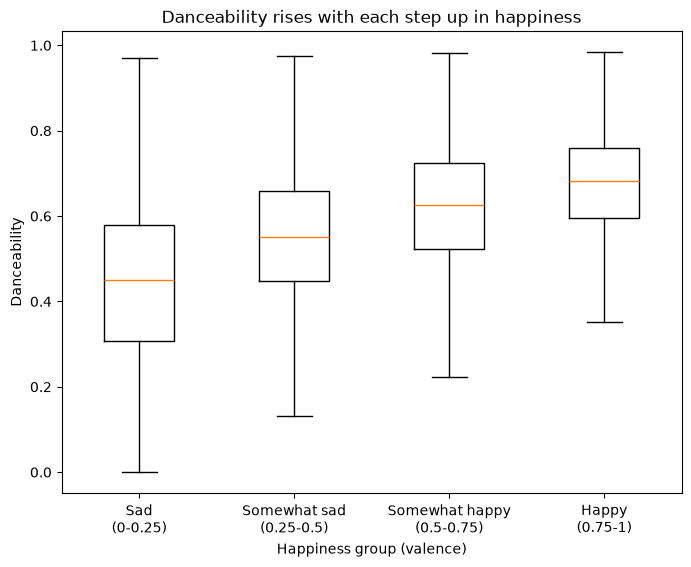

,count,mean,median
happiness_group,,,
Sad\n(0-0.25),27417,0.446,0.451
Somewhat sad\n(0.25-0.5),34568,0.550,0.551
Somewhat happy\n(0.5-0.75),31466,0.620,0.626
Happy\n(0.75-1),20549,0.673,0.681


In [29]:
# Split songs into 4 equal-width valence ranges
labels = ["Sad\n(0-0.25)", "Somewhat sad\n(0.25-0.5)", "Somewhat happy\n(0.5-0.75)", "Happy\n(0.75-1)"]
spotify_data['happiness_group'] = pd.cut(spotify_data['valence'], bins=[0, 0.25, 0.5, 0.75, 1.0],
                                         labels=labels, include_lowest=True)

# One list of danceability values per group, for the box plot
groups = [spotify_data.loc[spotify_data['happiness_group'] == g, 'danceability'] for g in labels]

fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(groups, showfliers=False)  # hide individual outlier dots to keep it readable
ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_xlabel("Happiness group (valence)")
ax.set_ylabel("Danceability")
ax.set_title("Danceability rises with each step up in happiness")
plt.show()

# Summary table: average and median danceability per group
spotify_data.groupby('happiness_group', observed=True)['danceability'].agg(['count', 'mean', 'median']).round(3)

## Answer

**Yes, happier songs are more danceable, though valence is far from the whole story.**

- **Moderate positive relationship:** r = 0.48. The regression line `danceability ≈ 0.32 × valence + 0.42` means the happiest songs average about 0.32 points more danceable than the saddest ones, on a 0-1 scale.
- **Consistent across groups:** average danceability rises at every step: about 0.45 for sad songs, 0.55 and 0.62 for the middle groups, and 0.67 for happy songs.
- **Only part of the picture:** R² = 0.23, so valence explains about 23% of the variation in danceability. The boxes overlap a lot, and plenty of sad songs are very danceable.
- **Correlation, not cause:** this shows the two traits go together. It doesn't show that making a song happier makes it more danceable. Both may be driven by genre, tempo or production style.